# Задание 4.2
## Рассадка 5 мужчин и 5 женщин в ряд

### Условие:
5 мужчин и 5 женщин случайным образом рассаживаются в ряд на 10 мест. Найдите вероятности событий: $A$ — любые две женщины не сидят рядом; $B$ — все мужчины сидят рядом.

### Теория и решение:
Люди различимы, исходы — расстановки людей по местам: $10!$ равновозможных. Условия событий $A$ и $B$ зависят только от того, **на каких местах сидят женщины** (остальные места — мужчины). Каждому набору из 5 мест для женщин соответствует одинаковое число $5!\cdot5!$ расстановок, поэтому все $C_{10}^5=252$ набора мест **равновозможны**, и можно считать $\Omega=\{$5-элементные подмножества $\{1,\dots,10\}\}$, $|\Omega|=252$.

**A (никакие две женщины не рядом).** Расставим сначала 5 мужчин, останется 6 «промежутков» (по краям и между мужчинами). В каждый промежуток можно посадить не более одной женщины: выбираем 5 из 6 промежутков: $C_6^5=6$ способов. Итак, $|A|=6$ и
$$\mathbb P(A)=\frac{6}{252}=\frac1{42}.$$
(Эти 6 наборов: $\{1,3,5,7,9\},\{1,3,5,7,10\},\{1,3,5,8,10\},\{1,3,6,8,10\},\{1,4,6,8,10\},\{2,4,6,8,10\}$.)

**B (все мужчины рядом).** Мужчины занимают 5 подряд идущих мест: первое место блока — любое из $1,\dots,6$, то есть 6 вариантов. Женщины занимают остальные места. $|B|=6$, 
$$\mathbb P(B)=\frac{6}{252}=\frac1{42}.$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from fractions import Fraction
from math import comb

rng = np.random.default_rng(2024)      # генератор псевдослучайных чисел; фиксированное «зерно» -> результаты воспроизводимы

def running_frequency(hits):
    # Относительная частота p̂_N = N(A)/N для N = 1, 2, ..., len(hits).
    # hits[i] = 1 (True), если в (i+1)-й реализации опыта событие A произошло, иначе 0.
    hits = np.asarray(hits, dtype=float)
    return np.cumsum(hits)/np.arange(1, len(hits) + 1)

def plot_frequency(ax, hits, p_exact, title, label=r'$\hat p_N(A)=N(A)/N$'):
    # График зависимости p̂(A) от числа реализаций N (статистическая устойчивость частоты):
    # синяя линия — относительная частота, красная — точная вероятность,
    # зелёные пунктиры — «коридор» P ± 3·sqrt(P(1−P)/N), в который частота попадает почти всегда.
    n = np.arange(1, len(hits) + 1)
    ph = np.cumsum(hits)/n
    sig = 3*np.sqrt(p_exact*(1 - p_exact)/n)
    ax.plot(n, ph, 'b-', lw=1, label=label)
    ax.axhline(p_exact, color='r', lw=1.5, label=f'P = {p_exact:.6f}')
    ax.plot(n, p_exact + sig, 'g--', lw=0.8, label=r'$P\pm3\sqrt{P(1-P)/N}$'); ax.plot(n, p_exact - sig, 'g--', lw=0.8)
    s = max(10, len(n)//50)                           # первые 2 % точек очень шумные; масштаб по y выбираем по остальным
    lo = min(ph[s:].min(), (p_exact - sig)[s:].min()); hi = max(ph[s:].max(), (p_exact + sig)[s:].max())
    pad = 0.1*(hi - lo); ax.set_ylim(lo - pad, hi + pad)
    ax.set_xlim(0, len(hits)); ax.grid(alpha=0.3); ax.set_xlabel('число реализаций опыта N'); ax.set_ylabel('относительная частота')
    ax.set_title(title, fontsize=10); ax.legend(fontsize=7.5, loc='upper right')

def plot_conditional(ax, hits_AB, hits_B, p_exact, title):
    # График условной частоты p̂(A|B) = N(A∩B)/N(B) в зависимости от общего числа реализаций N
    n = np.arange(1, len(hits_B) + 1); cB = np.cumsum(hits_B); cAB = np.cumsum(hits_AB)
    ph = np.where(cB > 0, cAB/np.maximum(cB, 1), np.nan)
    ax.plot(n, ph, 'b-', lw=1, label=r'$\hat p(A|B)=N(A\cap B)/N(B)$'); ax.axhline(p_exact, color='r', lw=1.5, label=f'значение {p_exact:.5f}')
    s = max(10, len(n)//20); v = ph[s:][~np.isnan(ph[s:])]; lo, hi = min(v.min(), p_exact), max(v.max(), p_exact); pad = 0.15*(hi - lo + 1e-9)
    ax.set_ylim(lo - pad, hi + pad); ax.set_xlim(0, len(hits_B)); ax.grid(alpha=0.3)
    ax.set_xlabel('число реализаций опыта N'); ax.set_ylabel('условная частота'); ax.set_title(title, fontsize=10); ax.legend(fontsize=7.5, loc='upper right')

def table(hits, p_exact, Ns=(100, 1000, 10_000, 100_000, 1_000_000)):
    # Печатает оценки p̂ при разных N, отклонение от точного значения и границу 3σ
    hits = np.asarray(hits, dtype=float)
    print('       N        p̂(N)        |p̂ − P|      3σ_N')
    for N in Ns:
        if N <= len(hits):
            ph = hits[:N].mean(); print(f'{N:9d}   {ph:.7f}   {abs(ph - p_exact):.2e}   {3*np.sqrt(p_exact*(1 - p_exact)/N):.2e}')

### Проверка полным перебором (252 набора мест)

In [2]:
from itertools import combinations

sets = list(combinations(range(1, 11), 5))                    # все способы выбрать 5 мест для женщин
def no_two_adjacent(w):                                       # A: нет двух соседних мест у женщин
    return all(b - a > 1 for a, b in zip(w, w[1:]))
def men_together(w):                                          # B: мужские места образуют отрезок из 5 подряд
    men = [i for i in range(1, 11) if i not in w]; return men[-1] - men[0] == 4
nA = sum(no_two_adjacent(w) for w in sets); nB = sum(men_together(w) for w in sets)
print(f'всего наборов: {len(sets)};  |A| = {nA};  |B| = {nB};  P(A) = {Fraction(nA, len(sets))};  P(B) = {Fraction(nB, len(sets))}')
print('наборы A:', [w for w in sets if no_two_adjacent(w)])

всего наборов: 252;  |A| = 6;  |B| = 6;  P(A) = 1/42;  P(B) = 1/42
наборы A: [(1, 3, 5, 7, 9), (1, 3, 5, 7, 10), (1, 3, 5, 8, 10), (1, 3, 6, 8, 10), (1, 4, 6, 8, 10), (2, 4, 6, 8, 10)]


### Моделирование: $N=300\,000$ случайных рассадок
Случайная перестановка людей = сортировка случайных чисел; первые 5 позиций в отсортированном порядке — «женщины».

In [3]:
N = 300_000
women = np.zeros((N, 10), dtype=bool)                          # women[i, j] = True, если на месте j в i-м опыте сидит женщина
perm = np.argsort(rng.random((N, 10)), axis=1)                 # случайная перестановка 0..9 для каждого опыта
np.put_along_axis(women, perm[:, :5], True, axis=1)            # первые 5 элементов перестановки — места женщин

hit_A = ~(women[:, :-1] & women[:, 1:]).any(axis=1)            # нет пары соседних женщин
pos = np.where(~women, np.arange(10), np.nan)                  # номера мужских мест (остальные — nan)
hit_B = (np.nanmax(pos, axis=1) - np.nanmin(pos, axis=1)) == 4 # мужчины занимают отрезок длины 5
for name, h in [('A', hit_A), ('B', hit_B)]:
    print(f'--- событие {name}: P = 1/42 = {1/42:.7f}'); table(h, 1/42, Ns=(100, 1000, 10_000, 100_000, 300_000))

--- событие A: P = 1/42 = 0.0238095
       N        p̂(N)        |p̂ − P|      3σ_N
      100   0.0300000   6.19e-03   4.57e-02
     1000   0.0280000   4.19e-03   1.45e-02
    10000   0.0260000   2.19e-03   4.57e-03
   100000   0.0243800   5.70e-04   1.45e-03
   300000   0.0242633   4.54e-04   8.35e-04
--- событие B: P = 1/42 = 0.0238095
       N        p̂(N)        |p̂ − P|      3σ_N
      100   0.0200000   3.81e-03   4.57e-02
     1000   0.0240000   1.90e-04   1.45e-02
    10000   0.0267000   2.89e-03   4.57e-03
   100000   0.0247000   8.90e-04   1.45e-03
   300000   0.0243000   4.90e-04   8.35e-04


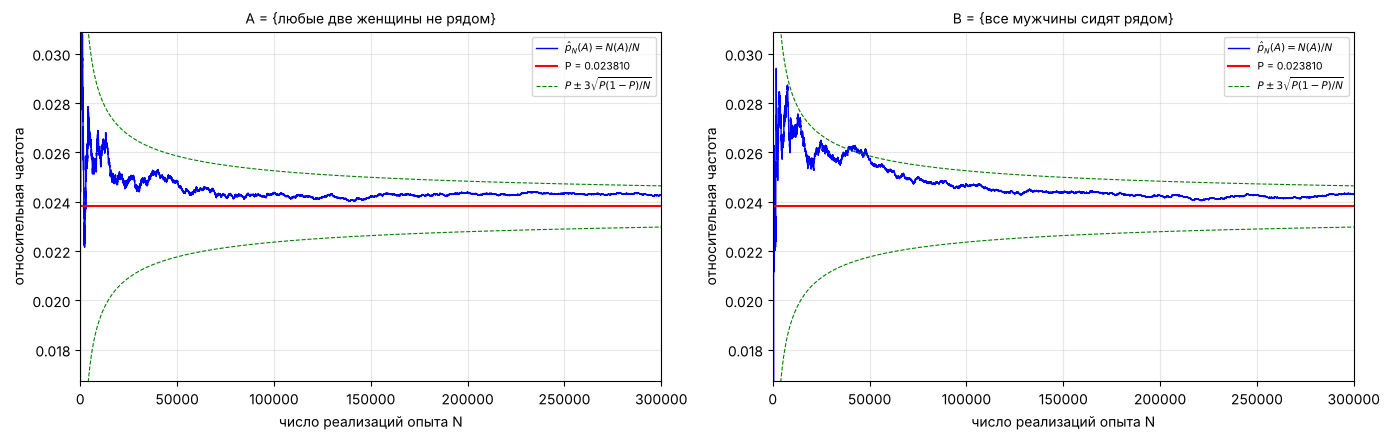

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(14, 4.5))
plot_frequency(axs[0], hit_A, 1/42, 'A = {любые две женщины не рядом}')
plot_frequency(axs[1], hit_B, 1/42, 'B = {все мужчины сидят рядом}')
plt.tight_layout(); plt.savefig('task_4_2.png', dpi=130, bbox_inches='tight'); plt.show()

### Ответ:
$\mathbb P(A)=\mathbb P(B)=\dfrac1{42}\approx0{,}0238$ (подтверждено перебором и моделированием).